# Interpretation and recommendations

Forecasting Indonesian CPI with Statistical and Machine Learning Models

Author: Wawan Saputra

Scope: Data tahunan tidak mendukung identifikasi musim dalam satu tahun. Karena itu SARIMA musiman dan seasonal decomposition tidak dipaksakan; tersedia dekomposisi trend/remainder deskriptif. Cutoff tetap 2024; forecast 2025–2027 merupakan eksperimen retrospektif, bukan ramalan terkini.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
ROOT = ROOT.resolve()
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))

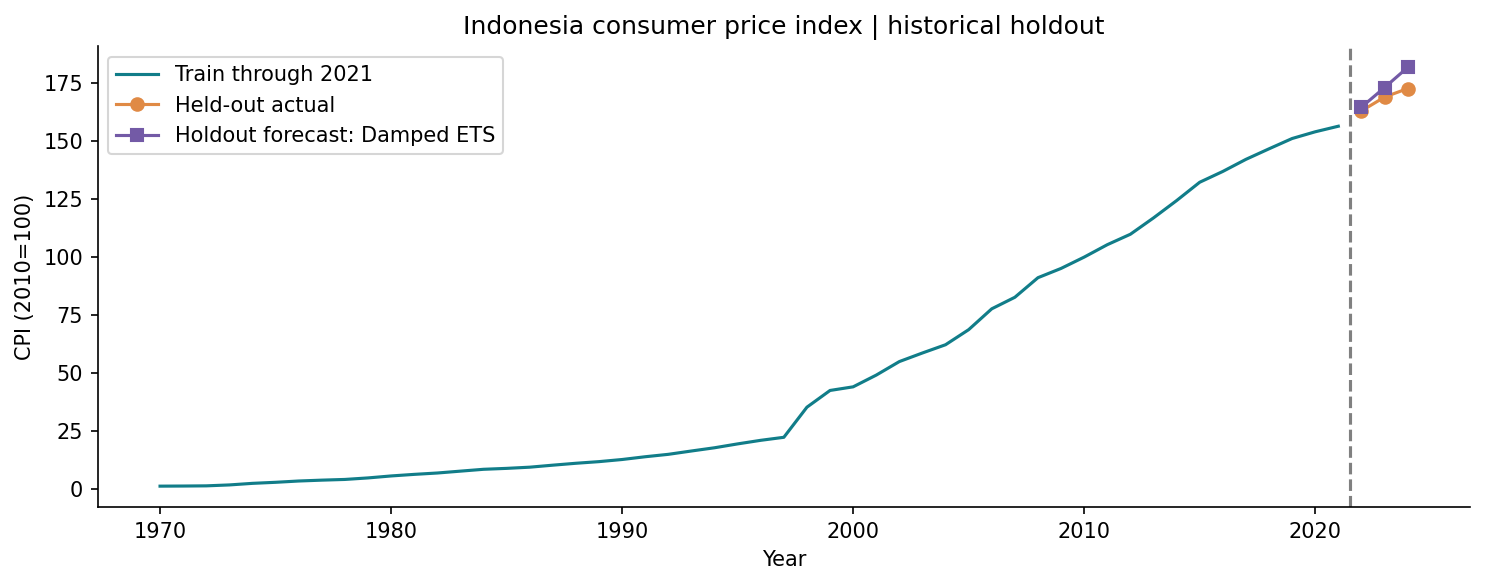

In [2]:
display(Image(filename=str(ROOT / 'outputs/figures/test_forecast.png')))

In [3]:
display(Markdown((ROOT / 'outputs/executive_summary.md').read_text(encoding='utf-8')))

# Forecasting Indonesian CPI with Statistical and Machine Learning Models

Wawan Saputra | Independent Portfolio Project | 2026

## Question and data

Forecast annual Indonesian CPI (2010=100), World Bank/IMF 1970–2024. Fixed historical cutoff; 2025–2027 forecasts are retrospective scenarios and are not current advice. Annual frequency cannot identify within-year seasonality; no artificial SARIMA seasonal period is imposed.

## Validation design

Expanding rolling origins 2009, 2012, 2015, 2018 with three-year horizons. Select lowest mean RMSE before final holdout 2022–2024. Models: naive, log drift, ARIMA(1,1,1) with drift, damped ETS on log CPI, and recursive random forest on three past log-growth lags.

## Actual results

Selected Damped ETS. Holdout MAE 4.952 CPI points; RMSE 5.847; MAPE 2.90%. Training residual Ljung–Box lag-5 p=0.4121.

| model              |      mae |     rmse |   mape_pct |
|:-------------------|---------:|---------:|-----------:|
| Damped ETS         |  7.60952 |  8.39896 |    5.65373 |
| Random Forest lags | 10.2166  | 11.1543  |    7.9005  |
| Naive              | 10.3665  | 11.1632  |    8.06819 |
| ARIMA(1,1,1)       | 16.1606  | 18.3872  |   11.8562  |
| Drift              | 18.8488  | 20.8488  |   13.9484  |

## Interpretation and recommendations

CPI levels and inflation rates are distinct. Exponentiated log forecasts are median-scale forecasts, not bias-corrected means. Use annual estimates for broad scenario planning; obtain monthly data for seasonal decisions. Crisis observations are flagged, retained and not automatically removed. ADF/Ljung–Box are diagnostic tools, not proofs of validity.

## Limitations and Future Work

Few observations, structural breaks and revised latest-vintage historical data. Backtest is not real-time vintage evaluation. No exogenous predictors. Forecast intervals are supplied only when the selected ARIMA model provides model-based intervals; other models have point forecasts, not fabricated intervals. Future: monthly CPI, broader origin sensitivity, interval calibration and real-time vintage data.

## CV-ready bullets

- Compared five annual CPI forecasting models across four rolling origins and a three-year held-out period.

- Selected Damped ETS using pre-test RMSE; achieved held-out RMSE 5.847 CPI points with ADF and residual diagnostics.
